### Imports

In [ ]:
# base imports 
import zipfile
from zipfile import ZipFile
from pathlib import Path
import warnings 
import random
import copy

# pandas & numpy 
import pandas as pd 
import numpy as np

# sklearn 
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

#  visualization part
import matplotlib.pyplot as plt 
from tqdm.auto import tqdm 

# torch base 
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader 

# transforms and work to image 
from torchvision.transforms import v2 
from PIL import Image

# for read data from tfrec 
from tfrecord.reader import tfrecord_loader

# recording 
plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore")

### Configs

In [ ]:
# determine configs 
SEED = 2026
N_SPLITS = 5
BATCH_SIZE = 64
NUM_EPOCHS = 50
LR = 1e-3

DEV = torch.device("mps" 
if torch.backends.mps.is_available()
else "cuda"
if torch.cuda.is_available()
else "cpu")

print(f"device: {DEV}")

device: mps


### Download and unzipping data

In [ ]:
# download and unzipping data 
DATA_PATH = Path("data")
FILE_PATH = DATA_PATH / "tpu-getting-started"
FILE_PATH.mkdir(parents=True, exist_ok=True)
FILE_PATH_ZIP = DATA_PATH / "tpu-getting-started.zip"

with zipfile.ZipFile(FILE_PATH_ZIP, "r") as ref_zip:
    print(f"Unzipping flowers data in {FILE_PATH} ...")
    ref_zip.extractall(FILE_PATH)

Unzipping flowers data in data/tpu-getting-started ...


### Transform from ".tfrec" to ".csv" 

In [ ]:
# make function for convert from ".tfrec" to ".csv"
SRC = Path("data/tpu-getting-started/tfrecords-jpeg-224x224")
DST = Path("data/flowers-224")

def convert_split(split: str, labeled: bool = True):

    out_dir = DST / split
    out_dir.mkdir(parents=True, exist_ok=True)

    description = {"image": "byte", "id": "byte"}

    if labeled:
        description["class"] = "int"

    rows = []
    for tfrec in tqdm(sorted((SRC / split).glob("*.tfrec"))):
        for rec in tfrecord_loader(str(tfrec), None, description):

            img_id = rec["id"].decode()
            (out_dir / f"{img_id}.jpg").write_bytes(rec["image"])

            row = {"id": img_id}
            if labeled:
                row["label"] = int(rec["class"][0])

            rows.append(row)

    pd.DataFrame(rows).to_csv(DST / f"{split}.csv", index=False)
    print(len(rows))

In [ ]:
# convert from ".tfrec" to ".csv"
convert_split("train")
convert_split("val")
convert_split("test", labeled=False)

  0%|          | 0/16 [00:00<?, ?it/s]

12753


  0%|          | 0/16 [00:00<?, ?it/s]

3712


  0%|          | 0/16 [00:00<?, ?it/s]

7382


### Custom dataset

In [ ]:
# make custom dataset 
class FlowersDataset(Dataset):

    def __init__(self, csv_path, img_path, transform=None):
        self.df = pd.read_csv(csv_path)
        self.img_path = Path(img_path) 
        self.transform = transform
        self.has_labels = "label" in self.df.columns

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(self.img_path / f"{row['id']}.jpg").convert("RGB")

        if self.transform:
            image = self.transform(image)

        if self.has_labels:
            return image, torch.tensor(row["label"], dtype=torch.long)

        return image, row["id"]

### Transforms

In [ ]:
# train and test transforms 
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = v2.Compose([
    v2.ToImage(),

    v2.RandomResizedCrop(224, scale=(0.7, 1.0)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomRotation(degrees=15),
    v2.ColorJitter(brightness=0.2, contrast=0.2,
                   saturation=0.2, hue=0.02),

    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_tf = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

### Transforms data to torch.dataset

In [ ]:
# transforms data to torch.dataset 
ROOT = Path("data/flowers-224")

train_ds_trans = FlowersDataset(ROOT / "train.csv", ROOT / "train", transform=train_tf)
val_ds_trans = FlowersDataset(ROOT / "val.csv", ROOT / "val", transform=eval_tf)
test_ds_trans = FlowersDataset(ROOT / "test.csv", ROOT / "test", transform=eval_tf)

In [ ]:
# check columns in our train dataset
train_ds_trans.df.columns

Index(['id', 'label'], dtype='object')

In [ ]:
# check count classes
classes = torch.unique(torch.tensor(train_ds_trans.df["label"].values)).tolist()
print(f"Num classes: {len(classes)}")

Num classes: 104


### Visualization data

In [ ]:
# make function for fast visualization 
IMAGENET_MEAN_T = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
IMAGENET_STD_T = torch.tensor(IMAGENET_STD).view(3, 1, 1)

def make_plots(
        data,
        rows: int=3,
        cols: int=3,
        seed=SEED):
    
    random.seed(seed)
    n = rows * cols
    random_indexes = random.sample(range(len(data)), k=n)
    fig, axes = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))

    for ax, index in zip(axes.flatten(), random_indexes):
        img, label = data[index]
        class_name = label.item()

        if isinstance(img, Image.Image):
            ax.imshow(img)
        else:
            # img = img * IMAGENET_STD_T + IMAGENET_MEAN_T
            img = img.clamp(0, 1)
            ax.imshow(img.permute(1, 2, 0))

        ax.set_title(f"Class: {class_name}", fontsize=15)
        ax.axis(False)
    plt.tight_layout()
    plt.show();

In [ ]:
# build train dataset (non transform) for visualization 
train_ds_non_trans = FlowersDataset(ROOT / "train.csv", ROOT / "train")

### Class distribution

In [ ]:
# check class distribution 
unique = train_ds_non_trans.df["label"].value_counts(ascending=True).reset_index(False)
unique_df = pd.DataFrame(unique)
unique_df

,label,count
0,44,18
1,6,18
2,34,18
3,38,19
4,20,19
...,...,...
99,53,460
100,49,563
101,4,703
102,103,743


### Before visualization

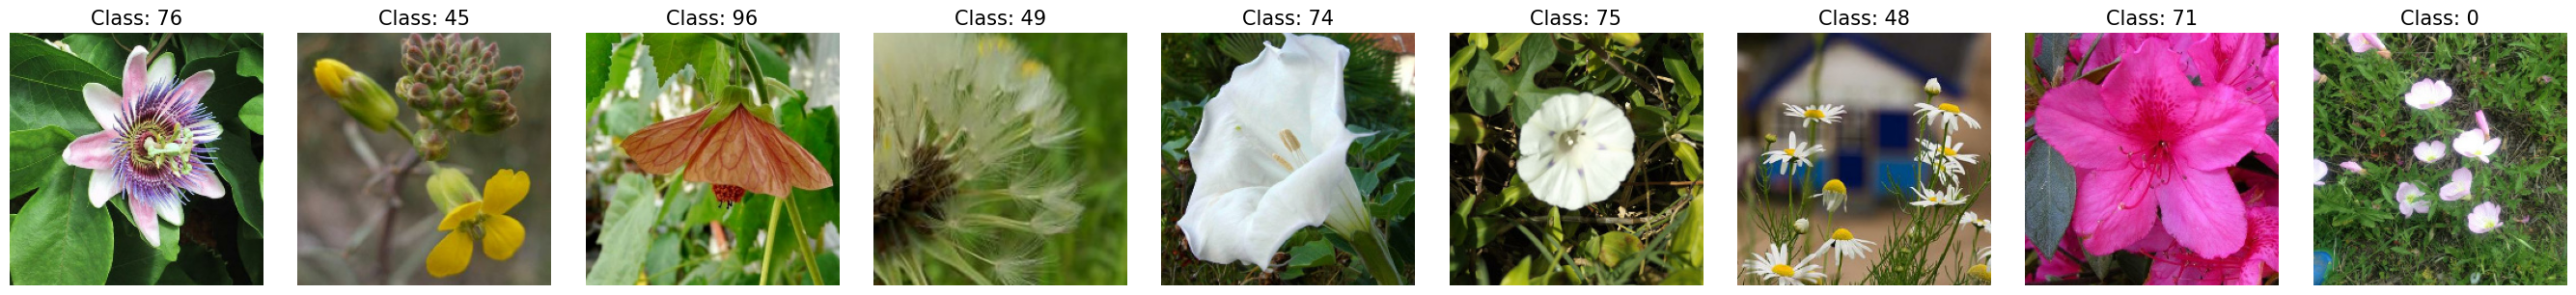

In [ ]:
# before visualization 
make_plots(train_ds_non_trans, rows=1, cols=9)

### After visualization

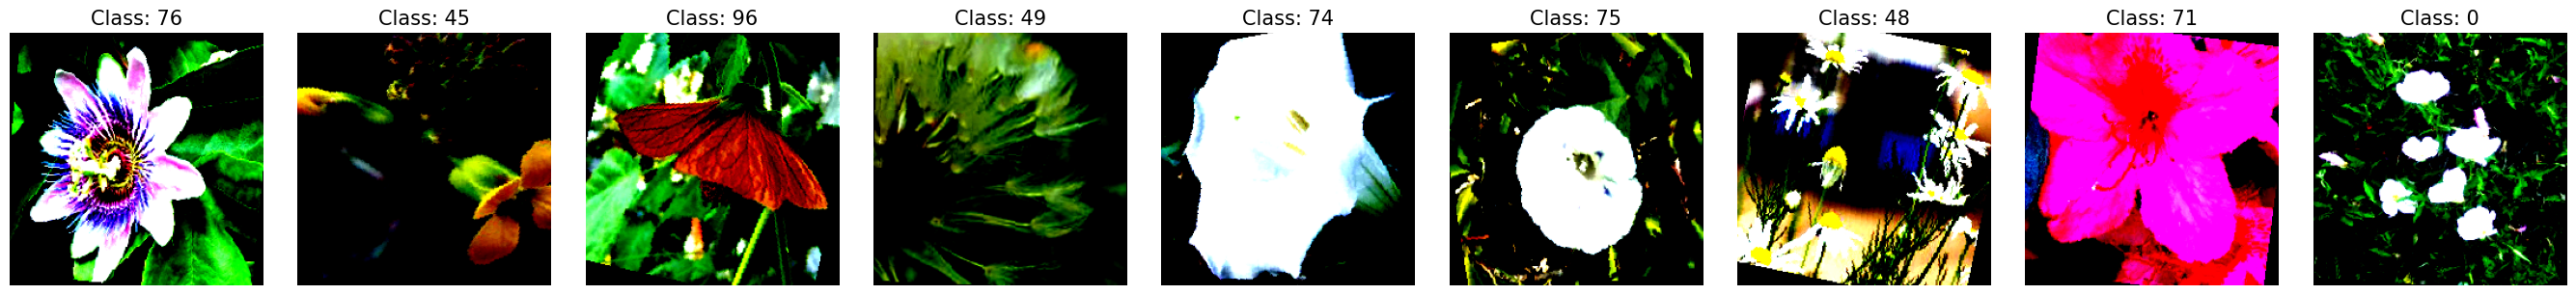

In [ ]:
# after visualization 
make_plots(train_ds_trans, rows=1, cols=9)

### Split data into batches

In [ ]:
# split data into batches 

train_loader = DataLoader(
    dataset=train_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    dataset=val_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    dataset=test_ds_trans,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

Shape: torch.Size([3, 224, 224]), 
Label: 69


In [ ]:
# for show 
images, labels = next(iter(train_loader))
print(f"Shape: {images[0].shape}, \nLabel: {labels[0]}")

### Custom CNN class

In [ ]:
# class custom model cnn 
class CustomFlowersModelv0(nn.Module):

    def __init__(self, input_shape: int=1, num_classes: int=104):
        super().__init__()

        def conv_block(in_f, out_f):
            return nn.Sequential(
                nn.Conv2d(in_channels=in_f, out_channels=out_f, kernel_size=3, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(out_f),
                nn.SiLU(),
                nn.Conv2d(in_channels=out_f, out_channels=out_f, kernel_size=3, stride=1, padding=1, bias=False),
                nn.BatchNorm2d(out_f),
                nn.SiLU()
            )
        
        self.features = nn.Sequential(
            conv_block(in_f=input_shape, out_f=32),
            conv_block(in_f=32, out_f=64),
            conv_block(in_f=64, out_f=128),
            conv_block(in_f=128, out_f=192)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(192, num_classes)
        )
        
    def forward(self, x):
        return self.classifier(self.features(x))

In [ ]:
# determine model 
torch.manual_seed(SEED)

custom_model = CustomFlowersModelv0(
    input_shape=3, 
    num_classes=len(classes)).to(DEV)

custom_model

CustomFlowersModelv0(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): SiLU()
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): SiLU()
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=Fal

### Train step

In [ ]:
# train step function 
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device):

    model.train()
    
    train_loss, train_acc = 0, 0
    all_preds, all_targets = [], []

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(DEV), y.to(device)
        y_loggits = model(X)

        loss = loss_fn(y_loggits, y)
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_preds = torch.argmax(y_loggits, dim=1)
        acc = (y_preds == y).sum().item() / len(y_loggits)
        train_acc += acc
        all_preds.append(y_preds.cpu())
        all_targets.append(y.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()
    train_f1 = f1_score(all_targets, all_preds, average="macro")
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    
    return train_loss, train_f1, train_acc

### Eval step

In [ ]:
# eval step function 
def eval_epoch(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               device: torch.device):

    total_loss, correct = 0, 0
    all_preds, all_targets = [], []
    model.eval()

    with torch.inference_mode():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = loss_fn(logits, y)
            total_loss += loss.item() * len(y)
            y_preds = torch.argmax(logits, dim=1)
            correct += (y_preds == y).sum().item()
            all_preds.append(y_preds.cpu())
            all_targets.append(y.cpu())

    all_preds = torch.cat(all_preds).numpy()
    all_targets = torch.cat(all_targets).numpy()

    n = len(dataloader.dataset)
    eval_loss = total_loss / n
    eval_f1 = f1_score(all_targets, all_preds, average="macro")
    eval_acc = correct / n

    return eval_loss, eval_f1, eval_acc

### Full step (train steps + eval steps)

In [ ]:
# full step function 
def full_step(model: torch.nn.Module,
              train_dataloader: torch.utils.data.DataLoader,
              val_dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              optimizer: torch.optim.Optimizer,
              epochs: int,
              device: torch.device,
              scheduler: torch.optim.lr_scheduler.LRScheduler):
    
    results = {"train_loss": [], "train_f1": [], "train_acc": [],
               "val_loss": [],   "val_f1": [],   "val_acc": []}

    best_f1 = 0.0
    best_state = None
    best_epoch = 0

    for epoch in tqdm(range(epochs)):
        train_loss, train_f1, train_acc = train_step(model=model,
                                        dataloader=train_dataloader,
                                        loss_fn=loss_fn,
                                        optimizer=optimizer,
                                        device=DEV)
        val_loss, val_f1, val_acc = eval_epoch(model=model,
                                               dataloader=val_dataloader,
                                               loss_fn=loss_fn,
                                               device=device)

        scheduler.step()

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            epoch = epoch+1

        print(f"Epoch {epoch+1:2d} | "
              f"Train Loss {train_loss:.3f} F1 {train_f1:.3f} Acc {train_acc:.3f} | "
              f"Val Loss {val_loss:.3f} F1 {val_f1:.3f} Acc {val_acc:.3f}")

        results["train_loss"].append(train_loss)
        results["train_f1"].append(train_f1)
        results["train_acc"].append(train_acc)
        results["val_loss"].append(val_loss)
        results["val_f1"].append(val_f1)
        results["val_acc"].append(val_acc)

    model.load_state_dict(best_state)                        
    print(f"Best Val F1 {best_f1:.3f} on Epoch {best_epoch}")

    return results

### Class weights (do not use)

In [ ]:
# class weights 
counts = train_ds_trans.df["label"].value_counts().sort_index()
weights = counts.sum() / (len(counts) * counts)
weights = torch.tensor(weights.values, dtype=torch.float32).to(DEV)

### Determine: Loss, Optimizer, Scheduler

In [ ]:
# determine loss, optimizer, scheduler 
torch.manual_seed(SEED)

loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(custom_model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer=optimizer, T_max=NUM_EPOCHS)

### Training model

In [ ]:
# training model
torch.manual_seed(SEED)

results = full_step(model=custom_model,
                    train_dataloader=train_loader,
                    val_dataloader=val_loader,
                    loss_fn=loss_fn,
                    optimizer=optimizer,
                    epochs=NUM_EPOCHS,
                    device=DEV,
                    scheduler=scheduler)

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch  2 | Train Loss 3.615 F1 0.027 Acc 0.143 | Val Loss 3.301 F1 0.038 Acc 0.177
Epoch  3 | Train Loss 3.249 F1 0.045 Acc 0.181 | Val Loss 3.086 F1 0.063 Acc 0.223
Epoch  4 | Train Loss 3.081 F1 0.075 Acc 0.217 | Val Loss 3.005 F1 0.080 Acc 0.221
Epoch  5 | Train Loss 2.924 F1 0.094 Acc 0.238 | Val Loss 2.948 F1 0.093 Acc 0.239
Epoch  6 | Train Loss 2.799 F1 0.118 Acc 0.269 | Val Loss 2.667 F1 0.129 Acc 0.296
Epoch  6 | Train Loss 2.675 F1 0.146 Acc 0.290 | Val Loss 2.630 F1 0.127 Acc 0.299
Epoch  8 | Train Loss 2.592 F1 0.167 Acc 0.312 | Val Loss 2.559 F1 0.187 Acc 0.318
Epoch  8 | Train Loss 2.488 F1 0.202 Acc 0.337 | Val Loss 2.665 F1 0.133 Acc 0.292
Epoch 10 | Train Loss 2.391 F1 0.231 Acc 0.365 | Val Loss 2.338 F1 0.243 Acc 0.373
Epoch 11 | Train Loss 2.326 F1 0.255 Acc 0.383 | Val Loss 2.273 F1 0.270 Acc 0.391
Epoch 12 | Train Loss 2.234 F1 0.286 Acc 0.406 | Val Loss 2.184 F1 0.291 Acc 0.419
Epoch 12 | Train Loss 2.154 F1 0.319 Acc 0.428 | Val Loss 2.161 F1 0.280 Acc 0.421
Epoc

### Predict function

In [ ]:
# make function for predict
def make_predictions(model: torch.nn.Module,
                     dataloader: torch.utils.data.DataLoader,
                     device: torch.device):

    model.eval()
    predictions = []

    with torch.inference_mode():
        for batch in dataloader:
            X = batch[0].to(device)
            y_loggits = model(X)
            y_preds = torch.argmax(y_loggits, dim=1)
            predictions.append(y_preds)
        
    return torch.cat(predictions)

### Predict

In [ ]:
# predict
test_pred = make_predictions(model=custom_model,
                             dataloader=test_loader,
                             device=DEV)

### Save predict

In [ ]:
# save predict
submission = pd.DataFrame({"id": test_ds_trans.df["id"],
                           "label": test_pred.cpu().numpy()})

submission.to_csv("submission.csv", index=False)
submission

,id,label
0,252d840db,67
1,dfd946ac8,45
2,0c3ae4377,81
3,a31f90373,67
4,0bf251179,73
...,...,...
7377,0cf33d505,49
7378,44af20a55,88
7379,6273f48ef,14
7380,3875d3601,53
